In [5]:
import pandas as pd
from prophet import Prophet

In [6]:
df = pd.read_csv('..\\preprocess\parking_time_series_with_features.csv')
df = df.rename(columns={'Time': 'ds', 'Parkings': 'y'})
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\p'
<>:1: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Viktor\AppData\Local\Temp\ipykernel_80060\1627081000.py:1: SyntaxWarning: invalid escape sequence '\p'
  df = pd.read_csv('..\\preprocess\parking_time_series_with_features.csv')


,ds,y,day_of_year,weekday,hour,is_holiday
0,2021-10-11 00:10:00,1,284,1,0,0
1,2021-10-11 00:11:00,1,284,1,0,0
2,2021-10-11 00:12:00,1,284,1,0,0
3,2021-10-11 00:13:00,1,284,1,0,0
4,2021-10-11 00:14:00,1,284,1,0,0


In [7]:
m = Prophet()
m.fit(df)

future = m.make_future_dataframe(periods=14)
future.tail()

forecast = m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()


12:29:03 - cmdstanpy - INFO - Chain [1] start processing
12:30:02 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
138240,2022-01-25,155.284851,-107.569698,404.148388
138241,2022-01-26,143.794068,-113.693597,421.903809
138242,2022-01-27,175.096683,-120.708962,487.215443
138243,2022-01-28,147.924806,-148.278046,476.817163
138244,2022-01-29,150.989931,-201.247394,511.879491


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\prophet\plot.py:72: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  fcst_t = fcst['ds'].dt.to_pydatetime()
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\prophet\plot.py:73: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  ax.plot(m.history['ds'].dt.to_pydatetime(), m.history['y'], 'k.',
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\prophet\plot.py:228: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series c

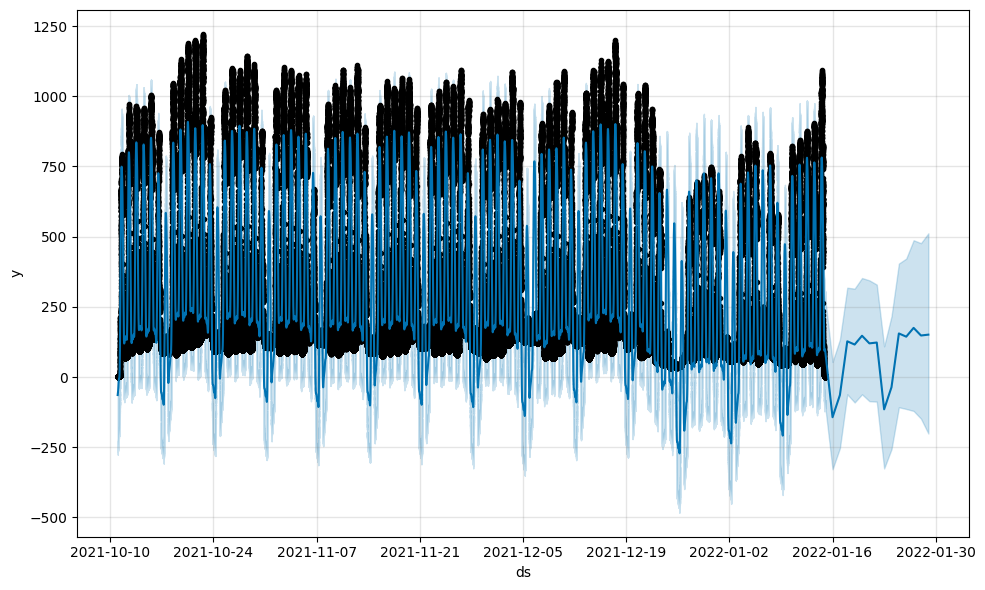

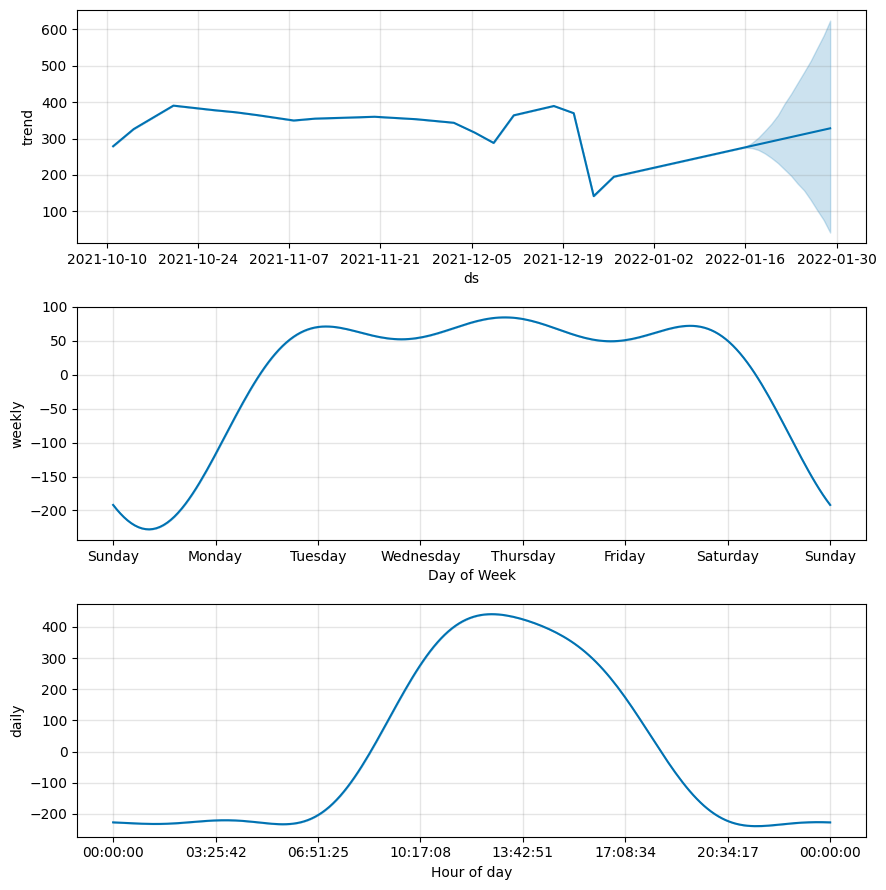

In [8]:
fig1 = m.plot(forecast)

fig2 = m.plot_components(forecast)
